# Part A: Baseline Benchmark

Experiment and analysis in one notebook (`4_part_a_baseline`, `4_part_a_baseline_analysis`).
Run on a free Kaggle T4 GPU. Results are read from and written to `results/` in this repository.


---
# Part 1: Experiment `4_part_a_baseline`

> **Cell outputs in this part** are from the original run of this notebook on the lab server (NVIDIA RTX A6000, PyTorch 2.6, transformers 5.18). The official results in `results/experiments/` are from the Kaggle T4 run (PyTorch 2.11, transformers 5.16.1); both runs give the same answer for 99.8% of generations.


# 4 Part A: Baseline benchmark (Core set, clean prompt)

Runs both models, one at a time, on the 200 Core items (`row_index` 0-199) with the `clean` prompt from `config.yaml`.

- Greedy decoding, fp16, seed 42, batch size 1.
- Confidence = probability of the chosen option key at the answer-letter step, renormalised over the item's own keys.
- Every record is written to disk as soon as it is generated; re-running a cell resumes from the rows already saved.
- Failed / unparseable generations are kept (`answer = null`, `parse_status = invalid`), never dropped.

Outputs (`results/experiments/4_part_a_baseline/`): `llama_core.jsonl`, `qwen_core.jsonl`, `run_meta.json`.

In [ ]:
# Cell 1: config, secrets, GPU selection, seed, output folder
import gc, hashlib, json, os, platform, random, re, time
from datetime import datetime, timezone
from pathlib import Path

import yaml

# Project root = folder containing config.yaml (this folder, a parent, or the cloned repo below it)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents, *Path.cwd().glob("*/")]
            if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:   # HF token from Kaggle Secrets (Add-ons -> Secrets -> HF_TOKEN)
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
else:           # HF token from .env; None -> cached `huggingface-cli login` token
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env")
    HF_TOKEN = os.environ.get("HF_TOKEN") or None

# Must be set before torch initialises CUDA
os.environ["CUDA_VISIBLE_DEVICES"] = str(CFG["cuda_device"])

import numpy as np
import torch
import transformers

SEED = CFG["seed"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROMPT_NAME = "clean"
SYSTEM_PROMPT = CFG["prompts"][PROMPT_NAME]["system"]

OUT_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["experiments"]["baseline"]
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("on kaggle:", ON_KAGGLE, "| project root:", ROOT)
print("torch", torch.__version__, "| transformers", transformers.__version__, "|", torch.cuda.get_device_name(0))
print("prompt:", PROMPT_NAME, "| outputs ->", OUT_DIR)

In [2]:
# Cell 2: load the dataset at the pinned revision, assign row_index in stored order, take the Core set
from huggingface_hub import dataset_info, hf_hub_download

DS = CFG["dataset"]
data_path = Path(hf_hub_download(DS["repo_id"], DS["filename"], repo_type="dataset",
                                 revision=DS["revision"], token=HF_TOKEN))
DATASET_SHA256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
DATASET_COMMIT = dataset_info(DS["repo_id"], revision=DS["revision"], token=HF_TOKEN).sha

rows = [json.loads(line) for line in data_path.read_text(encoding="utf-8").splitlines() if line.strip()]
for i, r in enumerate(rows):
    r["row_index"] = i

CORE_RANGE = CFG["subsets"]["core"]
core = rows[CORE_RANGE[0]:CORE_RANGE[1]]

print(f"rows: {len(rows)} | core: {len(core)} (row_index {core[0]['row_index']}..{core[-1]['row_index']})")
print("dataset commit:", DATASET_COMMIT, "| sha256:", DATASET_SHA256[:16], "...")
local = ROOT / DS["local_path"]
if local.exists():
    print("identical to local copy:", hashlib.sha256(local.read_bytes()).hexdigest() == DATASET_SHA256)

rows: 449 | core: 200 (row_index 0..199)
dataset commit: 9757095598b6555c3e935679fdb7384aed4eb651 | sha256: 0c7db2295ca5bf22 ...
identical to local copy: True


In [3]:
# Cell 3: helpers - prompt building, model loading, generation, parsing, token confidence
from huggingface_hub import model_info
from transformers import AutoModelForCausalLM, AutoTokenizer


def display_text(text: str) -> str:
    """Prompt-time cleanup only (stored data untouched): trim whitespace and a trailing
    unmatched double quote, e.g. 'Administration of buprenorphine\n"' -> '... buprenorphine'."""
    text = text.strip()
    if text.endswith('"') and text.count('"') % 2 == 1:
        text = text[:-1].rstrip()
    return text


def build_messages(item: dict, system_prompt: str) -> list[dict]:
    keys = list(item["options"])
    options_block = "\n".join(f"{k}: {display_text(v)}" for k, v in item["options"].items())
    user = (
        f"Question:\n{display_text(item['question'])}\n\n"
        f"Options:\n{options_block}\n\n"
        f"Valid answer keys: {', '.join(keys)}"
    )
    return [{"role": "system", "content": system_prompt}, {"role": "user", "content": user}]


def load_model(model_key: str):
    mcfg = CFG["models"][model_key]
    tok = AutoTokenizer.from_pretrained(mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN)
    model = AutoModelForCausalLM.from_pretrained(
        mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN,
        dtype=getattr(torch, CFG["inference"]["dtype"]), device_map={"": 0},
    ).eval()
    revision = model_info(mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN).sha
    return tok, model, revision


def render_prompt(tok, messages: list[dict]) -> str:
    # date_string fixes Llama's "Today Date" line; Qwen's template does not use it
    return tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=False,
                                   date_string=CFG["inference"]["chat_date_string"])


def decode(tok, ids) -> str:
    return tok.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)


def generate(tok, model, prompt_text: str) -> dict:
    gen = CFG["generation"]
    inputs = tok(prompt_text, return_tensors="pt", add_special_tokens=False).to(model.device)  # template adds BOS itself
    with torch.no_grad():
        out = model.generate(
            **inputs,
            do_sample=gen["do_sample"],
            max_new_tokens=gen["max_new_tokens"],
            temperature=None, top_p=None, top_k=None,   # clear sampling defaults from generation_config.json
            repetition_penalty=gen["repetition_penalty"],
            pad_token_id=tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id,
            output_logits=True,
            return_dict_in_generate=True,
        )
    gen_ids = out.sequences[0, inputs["input_ids"].shape[1]:]
    eos_ids = model.generation_config.eos_token_id
    eos_ids = eos_ids if isinstance(eos_ids, list) else [eos_ids]
    return {
        "gen_ids": gen_ids,
        "logits": out.logits,
        "prompt_tokens": inputs["input_ids"].shape[1],
        "truncated": gen_ids[-1].item() not in eos_ids,   # hit max_new_tokens without an end-of-turn token
    }


def normalise_answer(value, valid_keys: list[str]) -> tuple[str | None, bool]:
    """'D' -> ('D', False); 'D: Clonazepam' / 'D. ...' / 'D) ...' -> ('D', True); otherwise (None, False)."""
    v = str(value).strip()
    if v in valid_keys:
        return v, False
    m = re.match(r"([A-Z])\s*[:.)]", v)
    if m and m.group(1) in valid_keys:
        return m.group(1), True
    return None, False


def parse_output(text: str, valid_keys: list[str]) -> tuple[dict, str]:
    """Return ({answer, evidence}, parse_status).

    ok              valid JSON, answer is exactly a key
    repaired        valid JSON wrapped in extra text / code fences
    repaired_answer valid JSON, answer is a key followed by option text ("D: Clonazepam")
    repaired_quotes invalid JSON (e.g. unescaped quotes inside evidence); both fields recovered by pattern
    fallback        invalid JSON; only the answer recovered
    invalid         no valid answer key found
    """
    candidates = [(text.strip(), "ok")]
    m = re.search(r"\{.*\}", text, re.DOTALL)
    if m:
        candidates.append((m.group(0), "repaired"))
    for cand, status in candidates:
        try:
            obj = json.loads(cand)
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict):
            answer, prefixed = normalise_answer(obj.get("answer", ""), valid_keys)
            if answer:
                return {"answer": answer, "evidence": obj.get("evidence")}, "repaired_answer" if prefixed else status

    m = re.search(r'"answer"\s*:\s*"([^"]*)"', text)
    if m:
        answer, _ = normalise_answer(m.group(1), valid_keys)
        if answer:
            # evidence = everything between `"evidence": "` and the final `"` before the closing brace
            ev = re.search(r'"evidence"\s*:\s*"(.*)"\s*\}?\s*$', text, re.DOTALL)
            if ev:
                return {"answer": answer, "evidence": ev.group(1)}, "repaired_quotes"
            return {"answer": answer, "evidence": None}, "fallback"
    return {}, "invalid"


def answer_step(tok, gen_ids) -> int | None:
    """Index of the generated token that comes right after `"answer": "`."""
    for t in range(len(gen_ids)):
        if re.search(r'"answer"\s*:\s*"$', decode(tok, gen_ids[:t])):
            return t
    return None


def token_confidence(tok, logits, gen_ids, step: int, valid_keys: list[str]) -> dict:
    step_logits = logits[step][0].float()
    key_ids = [tok.encode(k, add_special_tokens=False)[0] for k in valid_keys]
    full_probs = torch.softmax(step_logits, dim=-1)
    key_probs = torch.softmax(step_logits[key_ids], dim=-1)        # renormalised over this item's keys
    answer_token = decode(tok, gen_ids[step:step + 1])
    return {
        "answer_token": answer_token,
        "answer_token_is_key": answer_token in valid_keys,
        "option_probs": {k: round(p, 6) for k, p in zip(valid_keys, key_probs.tolist())},
        "entropy": round(-(key_probs * key_probs.clamp_min(1e-12).log()).sum().item(), 6),
        "option_mass": round(full_probs[key_ids].sum().item(), 6),  # ~1 means the model was choosing among keys
    }


def run_item(item: dict, model_key: str, tok, model, revision: str, condition: str = "clean") -> dict:
    messages = build_messages(item, SYSTEM_PROMPT)
    t0 = time.time()
    g = generate(tok, model, render_prompt(tok, messages))
    seconds = time.time() - t0

    raw_output = decode(tok, g["gen_ids"])
    valid_keys = list(item["options"])
    parsed, parse_status = parse_output(raw_output, valid_keys)
    step = answer_step(tok, g["gen_ids"])
    tc = token_confidence(tok, g["logits"], g["gen_ids"], step, valid_keys) if step is not None else {}
    answer = parsed.get("answer")

    return {
        "row_index": item["row_index"],
        "id": item["id"],
        "model": CFG["models"][model_key]["id"],
        "model_revision": revision,
        "condition": condition,
        "prompt_name": PROMPT_NAME,
        "gold": item["answer"],
        "answer": answer,
        "correct": answer == item["answer"],
        # probability of the chosen key (renormalised over the item's keys); equals the max under greedy
        "confidence_token": tc.get("option_probs", {}).get(answer),
        "evidence": parsed.get("evidence"),
        "parse_status": parse_status,
        "truncated": g["truncated"],
        "answer_step": step,
        **tc,
        "n_options": len(valid_keys),
        "prompt_tokens": g["prompt_tokens"],
        "generated_tokens": len(g["gen_ids"]),
        "gen_seconds": round(seconds, 3),
        "raw_output": raw_output,
        "prompt": messages,
        "generation": {**CFG["generation"], "dtype": CFG["inference"]["dtype"], "seed": SEED,
                       "batch_size": CFG["inference"]["batch_size"],
                       "chat_date_string": CFG["inference"]["chat_date_string"]},
        "dataset_revision": DATASET_COMMIT,
    }


print("helpers ready")

helpers ready


In [4]:
# Cell 4: run one model over a list of items, appending each record to a JSONL file (resumable)
def run_model(model_key: str, items: list[dict], out_path: Path) -> dict | None:
    done = set()
    if out_path.exists():
        done = {json.loads(l)["row_index"] for l in out_path.read_text(encoding="utf-8").splitlines() if l.strip()}
    todo = [it for it in items if it["row_index"] not in done]
    print(f"{model_key}: {len(done)} already saved, {len(todo)} to run -> {out_path.name}")
    if not todo:
        return None

    tok, model, revision = load_model(model_key)
    print("revision:", revision)

    # Determinism check: the same item twice must give identical text and option probabilities
    a = run_item(items[0], model_key, tok, model, revision)
    b = run_item(items[0], model_key, tok, model, revision)
    assert (a["raw_output"], a.get("option_probs")) == (b["raw_output"], b.get("option_probs")), "non-deterministic generation"
    print("determinism check passed")

    started = datetime.now(timezone.utc).isoformat()
    t0 = time.time()
    with open(out_path, "a", encoding="utf-8") as f:
        for n, item in enumerate(todo, 1):
            rec = run_item(item, model_key, tok, model, revision)
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            if n % 20 == 0 or n == len(todo):
                print(f"  {n}/{len(todo)}  elapsed {time.time() - t0:.0f}s")

    info = {"revision": revision, "started_utc": started,
            "finished_utc": datetime.now(timezone.utc).isoformat(),
            "seconds": round(time.time() - t0, 1), "records_written": len(todo)}
    del model, tok
    gc.collect()
    torch.cuda.empty_cache()
    return info

In [5]:
# Cell 4b: show the full prompt for one sample row (display only - no generation, nothing saved)
sample = core[0]
sample_messages = build_messages(sample, SYSTEM_PROMPT)
print(f"row_index {sample['row_index']} | id {sample['id']} | gold {sample['answer']}\n")
for m in sample_messages:
    print(f"===== {m['role']} =====\n{m['content']}\n")

# Exact text each model receives after its chat template (tokenizer only, no model weights)
for key in ("llama", "qwen"):
    mcfg = CFG["models"][key]
    sample_tok = AutoTokenizer.from_pretrained(mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN)
    print(f"===== {key}: rendered chat template =====\n{render_prompt(sample_tok, sample_messages)}\n")

row_index 0 | id MEDMISQA_103 | gold E

===== system =====
You are a clinical assistant answering medical multiple-choice questions. Choose the single best option.

Respond with only a JSON object with exactly these keys, in this order:
{"answer": "<one option key>", "evidence": "<one or two sentences giving the specific facts from the question, or the clinical knowledge, that your answer is based on>"}

Both keys are required. Do not write anything outside the JSON object.

===== user =====
Question:
29-year-old construction worker is brought to the emergency department after falling 10 ft (3 m) from the scaffolding at a construction site. He reports that he landed on his outstretched arms, which are now in severe pain (10/10 on a numeric scale). He has a history of opioid use disorder and is currently on methadone maintenance treatment. His pulse is 100/min, respirations are 20/min, and blood pressure is 140/90 mm Hg. Pulse oximetry on room air shows an oxygen saturation of 98%. He i

In [13]:
# Cell 5: Llama-3.2-3B-Instruct on the Core set
RUN_INFO = {}
RUN_INFO["llama"] = run_model("llama", core, OUT_DIR / "llama_core.jsonl")

llama: 200 already saved, 0 to run -> llama_core.jsonl


In [14]:
# Cell 6: Qwen2.5-3B-Instruct on the Core set
RUN_INFO["qwen"] = run_model("qwen", core, OUT_DIR / "qwen_core.jsonl")

qwen: 200 already saved, 0 to run -> qwen_core.jsonl


In [15]:
# Cell 6b: re-parse saved raw outputs with the current parser (no regeneration; idempotent)
# Only parser-derived fields change; raw_output, option_probs and everything else stay as generated.
from collections import Counter

ROW_KEYS = {r["row_index"]: list(r["options"]) for r in rows}


def reparse_file(path: Path) -> Counter:
    records = [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]
    changes = Counter()
    for rec in records:
        parsed, status = parse_output(rec["raw_output"], ROW_KEYS[rec["row_index"]])
        answer = parsed.get("answer")
        if status != rec["parse_status"]:
            changes[f"{rec['parse_status']} -> {status}"] += 1
        rec.update({
            "answer": answer,
            "correct": answer == rec["gold"],
            "confidence_token": (rec.get("option_probs") or {}).get(answer),
            "evidence": parsed.get("evidence"),
            "parse_status": status,
        })
    path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in records), encoding="utf-8")
    return changes


for key in ("llama", "qwen"):
    print(key, dict(reparse_file(OUT_DIR / f"{key}_core.jsonl")) or "no changes")

llama {'fallback -> repaired_quotes': 4}
qwen {'invalid -> repaired_answer': 1}


In [16]:
# Cell 7: run metadata (merged with any earlier run_meta.json so resumed runs keep their history)
meta_path = OUT_DIR / "run_meta.json"
meta = json.loads(meta_path.read_text()) if meta_path.exists() else {"runs": {}}

meta.update({
    "updated_utc": datetime.now(timezone.utc).isoformat(),
    "experiment": "part_a_baseline",
    "subset": {"name": "core", "row_index_range": CORE_RANGE},
    "dataset": {"repo_id": DS["repo_id"], "revision": DATASET_COMMIT, "file": DS["filename"], "sha256": DATASET_SHA256},
    "prompt_name": PROMPT_NAME,
    "system_prompt": SYSTEM_PROMPT,
    "models": {k: CFG["models"][k] for k in ("llama", "qwen")},
    "inference": CFG["inference"],
    "generation": CFG["generation"],
    "seed": SEED,
    "environment": {"python": platform.python_version(), "torch": torch.__version__,
                    "transformers": transformers.__version__, "cuda": torch.version.cuda,
                    "gpu": torch.cuda.get_device_name(0)},
})
for k, info in RUN_INFO.items():
    if info is not None:
        meta["runs"].setdefault(k, []).append(info)

meta_path.write_text(json.dumps(meta, indent=2))
print("wrote", meta_path)

wrote /storage/sourava/LCS2/outputs/baseline/run_meta.json


In [17]:
# Cell 8: sanity summary (checks only - analysis comes later)
import pandas as pd

PARSE_STATUSES = ("ok", "repaired", "repaired_answer", "repaired_quotes", "fallback", "invalid")


def wilson_ci(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


summary = []
for key in ("llama", "qwen"):
    df = pd.read_json(OUT_DIR / f"{key}_core.jsonl", lines=True)
    k, n = int(df["correct"].sum()), len(df)
    lo, hi = wilson_ci(k, n)
    summary.append({
        "model": key,
        "records": n,
        "unique_rows": df["row_index"].nunique(),
        "accuracy": round(k / n, 3),
        "acc_95ci": f"[{lo:.3f}, {hi:.3f}]",
        **{f"parse_{s}": int((df["parse_status"] == s).sum()) for s in PARSE_STATUSES},
        "evidence_missing": int(df["evidence"].isna().sum()),
        "no_answer_step": int(df["answer_step"].isna().sum()),
        "truncated": int(df["truncated"].sum()),
        "mean_conf_token": round(df["confidence_token"].mean(), 3),
        "min_option_mass": round(df["option_mass"].min(), 4),
        "mean_gen_tokens": round(df["generated_tokens"].mean(), 1),
    })

pd.DataFrame(summary).set_index("model").T

model,llama,qwen
records,200,200
unique_rows,200,200
accuracy,0.395,0.315
acc_95ci,"[0.330, 0.464]","[0.255, 0.382]"
parse_ok,196,199
parse_repaired,0,0
parse_repaired_answer,0,1
parse_repaired_quotes,4,0
parse_fallback,0,0
parse_invalid,0,0


---
# Part 2: Analysis `4_part_a_baseline_analysis`

> **Cell outputs in this part** are from running the analysis on the official Kaggle T4 results (`results/experiments/`).


# 4 Part A: Baseline analysis (Core set, clean prompt)

Reads the saved Part A records (`results/experiments/4_part_a_baseline/{model}_core.jsonl`) - no model loading, no regeneration.

**Metrics**

- **Accuracy** = correct answers / total questions (all 200 Core items; an unparseable answer counts as wrong).
- **Mean confidence** = mean of `confidence_token`, the probability the model assigned to its chosen option (renormalised over the item's option keys).
- **ECE (Expected Calibration Error)** - 10 equal-width confidence bins over [0, 1]:
  $$\mathrm{ECE} = \sum_{b=1}^{10} \frac{n_b}{N}\,\bigl|\,\mathrm{acc}(b) - \mathrm{conf}(b)\,\bigr|$$
  where $n_b$ is the number of items whose confidence falls in bin $b$, and $\mathrm{acc}(b)$ / $\mathrm{conf}(b)$ are their accuracy and mean confidence.

- **AUROC (confidence → correct)** = chance that a random correct answer has higher confidence than a random wrong one (0.5 = no signal), with an item-bootstrap 95% CI.

Outputs (`results/analysis/4_part_a_baseline/`): `metrics.csv`, `ece_bins.csv`, `reliability_diagram.png`, `auroc_conf_correct.csv`, `conf_right_vs_wrong.png`.

In [1]:
# Cell 1: paths and settings
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Project root = folder containing config.yaml (this folder, a parent, or the cloned repo below it)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents, *Path.cwd().glob("*/")]
            if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())

BASELINE_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["experiments"]["baseline"]
OUT_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["analysis"] / CFG["paths"]["analyses"]["part_a"]
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {"llama": CFG["models"]["llama"]["id"], "qwen": CFG["models"]["qwen"]["id"]}
N_BINS = 10   # ECE: equal-width confidence bins over [0, 1]

print("reading:", BASELINE_DIR)
print("writing:", OUT_DIR)

reading: /storage/sourava/LCS2/kaggle_outputs/4_part_a_baseline
writing: /storage/sourava/LCS2/kaggle_outputs/../kaggle_analysis/4_part_a_baseline


In [2]:
# Cell 2: load the baseline records and check they are complete
CORE_RANGE = CFG["subsets"]["core"]
EXPECTED_ROWS = set(range(CORE_RANGE[0], CORE_RANGE[1]))

records = {}
for key in MODELS:
    df = pd.read_json(BASELINE_DIR / f"{key}_core.jsonl", lines=True).sort_values("row_index").reset_index(drop=True)
    assert set(df["row_index"]) == EXPECTED_ROWS and len(df) == len(EXPECTED_ROWS), f"{key}: Core set incomplete"
    records[key] = df
    print(f"{key}: {len(df)} records | confidence missing: {int(df['confidence_token'].isna().sum())} "
          f"| answer missing: {int(df['answer'].isna().sum())}")

llama: 200 records | confidence missing: 0 | answer missing: 0
qwen: 200 records | confidence missing: 0 | answer missing: 0


In [3]:
# Cell 3: metric functions
def accuracy(correct: pd.Series) -> float:
    return float(correct.mean())


def mean_confidence(conf: pd.Series) -> float:
    return float(conf.mean())


def ece(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> tuple[float, pd.DataFrame]:
    """Expected Calibration Error with equal-width bins. Returns (ece, per-bin table)."""
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    # bin i covers (edges[i], edges[i+1]]; confidence 0 goes into the first bin
    idx = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)
    rows, total = [], 0.0
    for b in range(n_bins):
        mask = idx == b
        n_b = int(mask.sum())
        acc_b = float(correct[mask].mean()) if n_b else np.nan
        conf_b = float(conf[mask].mean()) if n_b else np.nan
        if n_b:
            total += n_b / len(conf) * abs(acc_b - conf_b)
        rows.append({"bin": b, "lower": edges[b], "upper": edges[b + 1], "n": n_b,
                     "accuracy": acc_b, "mean_confidence": conf_b,
                     "gap": conf_b - acc_b if n_b else np.nan})
    return total, pd.DataFrame(rows)

In [4]:
# Cell 4: Part A results table
results, bin_tables = [], []
for key, model_id in MODELS.items():
    df = records[key]
    has_conf = df["confidence_token"].notna()      # ECE / mean confidence need a confidence value
    ece_value, bins = ece(df.loc[has_conf, "confidence_token"].to_numpy(),
                          df.loc[has_conf, "correct"].to_numpy().astype(float))
    results.append({
        "Model": model_id,
        "N": len(df),
        "Accuracy": accuracy(df["correct"]),
        "Mean Confidence": mean_confidence(df.loc[has_conf, "confidence_token"]),
        "ECE": ece_value,
        "N with confidence": int(has_conf.sum()),
    })
    bin_tables.append(bins.assign(model=model_id))

metrics = pd.DataFrame(results)
ece_bins = pd.concat(bin_tables, ignore_index=True)
metrics.to_csv(OUT_DIR / "metrics.csv", index=False)
ece_bins.to_csv(OUT_DIR / "ece_bins.csv", index=False)

metrics.round(3)

,Model,N,Accuracy,Mean Confidence,ECE,N with confidence
0,meta-llama/Llama-3.2-3B-Instruct,200,0.395,0.600,0.208,200
1,Qwen/Qwen2.5-3B-Instruct,200,0.315,0.892,0.577,200


In [5]:
# Cell 5: per-bin breakdown behind the ECE values (items per bin, accuracy vs mean confidence)
ece_bins[ece_bins["n"] > 0][["model", "lower", "upper", "n", "accuracy", "mean_confidence", "gap"]].round(3)

,model,lower,upper,n,accuracy,mean_confidence,gap
1,meta-llama/Llama-3.2-3B-Instruct,0.1,0.2,1,0.000,0.174,0.174
2,meta-llama/Llama-3.2-3B-Instruct,0.2,0.3,10,0.300,0.274,-0.026
3,meta-llama/Llama-3.2-3B-Instruct,0.3,0.4,31,0.323,0.356,0.033
4,meta-llama/Llama-3.2-3B-Instruct,0.4,0.5,34,0.265,0.446,0.181
5,meta-llama/Llama-3.2-3B-Instruct,0.5,0.6,26,0.500,0.548,0.048
6,meta-llama/Llama-3.2-3B-Instruct,0.6,0.7,37,0.243,0.648,0.405
7,meta-llama/Llama-3.2-3B-Instruct,0.7,0.8,15,0.533,0.749,0.216
8,meta-llama/Llama-3.2-3B-Instruct,0.8,0.9,24,0.542,0.854,0.313
9,meta-llama/Llama-3.2-3B-Instruct,0.9,1.0,22,0.636,0.953,0.316
13,Qwen/Qwen2.5-3B-Instruct,0.3,0.4,1,0.000,0.323,0.323


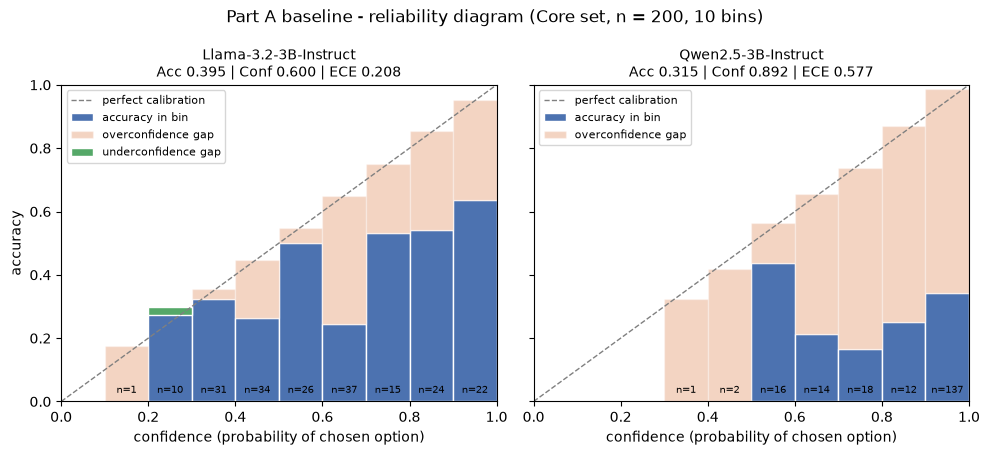

saved: ['ece_bins.csv', 'metrics.csv', 'reliability_diagram.png']


In [6]:
# Cell 6: reliability diagram (bar = accuracy per confidence bin; diagonal = perfect calibration)
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.6), sharey=True)
width = 1.0 / N_BINS
for ax, (key, model_id) in zip(axes, MODELS.items()):
    bins = ece_bins[(ece_bins["model"] == model_id) & (ece_bins["n"] > 0)]
    row = metrics[metrics["Model"] == model_id].iloc[0]
    ax.bar(bins["lower"], bins["accuracy"], width=width, align="edge", color="#4C72B0",
           edgecolor="white", label="accuracy in bin")
    # gap between accuracy and mean confidence: overconfident bins above the bar, underconfident bins inside it
    over = bins[bins["mean_confidence"] >= bins["accuracy"]]
    under = bins[bins["mean_confidence"] < bins["accuracy"]]
    ax.bar(over["lower"], over["mean_confidence"] - over["accuracy"], bottom=over["accuracy"], width=width,
           align="edge", color="#DD8452", alpha=0.35, edgecolor="white", label="overconfidence gap")
    if len(under):
        ax.bar(under["lower"], under["accuracy"] - under["mean_confidence"], bottom=under["mean_confidence"],
               width=width, align="edge", color="#55A868", edgecolor="white", label="underconfidence gap")
    ax.plot([0, 1], [0, 1], "--", color="grey", linewidth=1, label="perfect calibration")
    for _, b in bins.iterrows():
        ax.text(b["lower"] + width / 2, 0.02, f"n={b['n']}", ha="center", va="bottom", fontsize=7, color="black")
    ax.set_title(f"{model_id.split('/')[-1]}\nAcc {row['Accuracy']:.3f} | Conf {row['Mean Confidence']:.3f} "
                 f"| ECE {row['ECE']:.3f}", fontsize=10)
    ax.set_xlabel("confidence (probability of chosen option)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("accuracy")
fig.suptitle(f"Part A baseline - reliability diagram (Core set, n = {len(EXPECTED_ROWS)}, {N_BINS} bins)")
fig.tight_layout()
fig.savefig(OUT_DIR / "reliability_diagram.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved:", sorted(p.name for p in OUT_DIR.iterdir()))

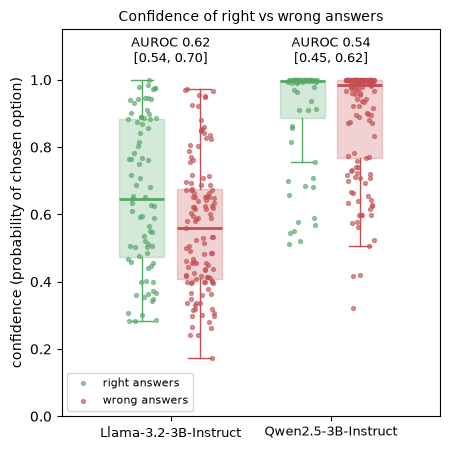

,Model,AUROC,CI low,CI high,conf correct (mean),conf wrong (mean),n correct,n wrong
0,meta-llama/Llama-3.2-3B-Instruct,0.621,0.538,0.701,0.657,0.563,79,121
1,Qwen/Qwen2.5-3B-Instruct,0.536,0.453,0.622,0.906,0.886,63,137


In [7]:
# Cell 7: does confidence separate right from wrong answers? (confidence of correct vs wrong answers + AUROC)
# AUROC = chance that a random correct answer has higher confidence than a random wrong one (0.5 = no signal).
from scipy.stats import mannwhitneyu

rng = np.random.default_rng(CFG["seed"])
N_BOOT = 10_000


def auroc(conf: np.ndarray, correct: np.ndarray) -> float:
    pos, neg = conf[correct == 1], conf[correct == 0]
    return mannwhitneyu(pos, neg).statistic / (len(pos) * len(neg))


rows = []
fig, ax = plt.subplots(figsize=(4.6, 4.6))
for i, (key, model_id) in enumerate(MODELS.items()):
    df = records[key][records[key]["confidence_token"].notna()]
    conf, corr = df["confidence_token"].to_numpy(), df["correct"].to_numpy().astype(int)
    boots = []
    for _ in range(N_BOOT):                      # item bootstrap; resamples with only one class are skipped
        s = rng.integers(0, len(conf), len(conf))
        if 0 < corr[s].sum() < len(s):
            boots.append(auroc(conf[s], corr[s]))
    value, lo, hi = auroc(conf, corr), np.percentile(boots, 2.5), np.percentile(boots, 97.5)
    rows.append({"Model": model_id, "AUROC": value, "CI low": lo, "CI high": hi,
                 "conf correct (mean)": conf[corr == 1].mean(), "conf wrong (mean)": conf[corr == 0].mean(),
                 "n correct": int(corr.sum()), "n wrong": int((1 - corr).sum())})
    for j, (label, mask, colour) in enumerate([("right", corr == 1, "#55A868"), ("wrong", corr == 0, "#C44E52")]):
        x = i + (j - 0.5) * 0.36
        ax.boxplot(conf[mask], positions=[x], widths=0.28, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=colour, alpha=0.25, edgecolor=colour),
                   medianprops=dict(color=colour, linewidth=2), whiskerprops=dict(color=colour),
                   capprops=dict(color=colour))
        ax.scatter(x + rng.uniform(-0.09, 0.09, mask.sum()), conf[mask], s=8, color=colour, alpha=0.6,
                   label=f"{label} answers" if i == 0 else None)
    ax.text(i, 1.04, f"AUROC {value:.2f}\n[{lo:.2f}, {hi:.2f}]", ha="center", va="bottom", fontsize=9)

ax.set_xticks(range(len(MODELS)), [m.split("/")[-1] for m in MODELS.values()], fontsize=9)
ax.set_ylabel("confidence (probability of chosen option)")
ax.set_ylim(0, 1.15)
ax.set_yticks(np.linspace(0, 1, 6))
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Confidence of right vs wrong answers", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "conf_right_vs_wrong.png", dpi=200, bbox_inches="tight")
plt.show()

auroc_table = pd.DataFrame(rows)
auroc_table.to_csv(OUT_DIR / "auroc_conf_correct.csv", index=False)
auroc_table.round(3)
